## MTSA EXAMPLE

### Some imports

In [ ]:
%load_ext autoreload
%autoreload 2

import sys

sys.path.append("..")

import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score

from examples.sample_data_utils import get_acoustic_sample_data, get_tabular_sample_data
from mtsa.losses.forward_loss import ForwardLoss
from mtsa.preprocessing.feature_extraction.non_parameterized.vec2mfcc import Array2Mfcc
from mtsa.losses.lagrange_loss import LagrangeLoss
from mtsa.losses.trace_exponential_matrix_loss import TraceExponentialMatrixLoss
from mtsa.models.hybrid.ganf import GANF
from mtsa.predictors.standard_predictor import StandardPredictor
from mtsa.trainers.lagrange_trainer import LagrangeTrainer
from mtsa.utils.data import get_dataloader
from mtsa.utils.plots import plot_roc_pr_curves
from mtsa.utils.utils import Wav2Array


## Building a model


### Ganf Model

#### Synthetic Data

In [ ]:
X_train, y_train, X_test, y_test = get_tabular_sample_data()

training_samples = get_dataloader(
    X_train,
    y_train,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

test_samples = get_dataloader(
    X_test,
    y_test,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

In [3]:
# Hypothesis set
model_ganf = GANF(
    n_blocks=6,
    input_features=1,
    hidden_size=32,
    n_hidden=1,
    model="MAF",
    device="cpu",
    time_series_amount=X_train.shape[1],
)

# Optimizer
weight_decay = 0.1
learning_rate = 1e-4
optimizer = torch.optim.Adam(
    [
        {"params": model_ganf.parameters(), "weight_decay": weight_decay},
        {"params": [model_ganf.adjacency_matrix]},
    ],
    lr=learning_rate,
    weight_decay=0.0,
)

# Error Measure
negative_log_prob_loss = ForwardLoss()
dag_loss = TraceExponentialMatrixLoss()
loss = LagrangeLoss(primal_loss=negative_log_prob_loss, dual_losses=[dag_loss])

In [4]:
# Learning algorithm
learning_algorithm = LagrangeTrainer()

learning_algorithm.fit(    
    model=model_ganf,
    optimizer=optimizer,
    loss=loss,
    train_loader = training_samples,
    epochs=2,
    interactions=2
)

Training: 100%|██████████| 4/4 [00:09<00:00,  2.47s/epoch, loss=-12.169281959533691]


GANF(
  (rnn): LSTM(1, 32, batch_first=True)
  (gcn): GNN(
    (lin_n): Linear(in_features=32, out_features=32, bias=True)
    (lin_r): Linear(in_features=32, out_features=32, bias=False)
    (lin_2): Linear(in_features=32, out_features=32, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (nf): MAF(
    (net): FlowSequential(
      (0): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, bias=True)
        )
      )
      (1): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, 

In [5]:
predict_algorithm = StandardPredictor()

y_hat, y = predict_algorithm.predict(function=model_ganf, dataloader=test_samples, pointwise=True, aggregation="mean")



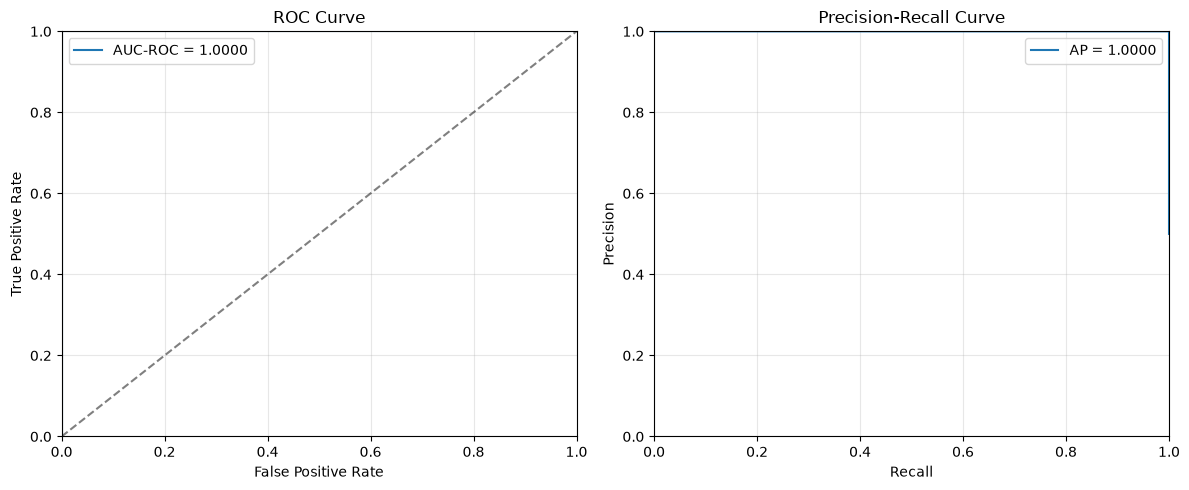

In [6]:
roc_auc, pr_auc = plot_roc_pr_curves(y, y_hat)

#### Acoustic Data

In [7]:
X_train, y_train, X_test, y_test = get_acoustic_sample_data()


preprocessing_steps = nn.Sequential(
    Wav2Array(sampling_rate=16000),
    Array2Mfcc(sampling_rate=16000),
)

X_train = preprocessing_steps(X_train)
X_test = preprocessing_steps(X_test)

X_train = torch.permute(X_train,(0,2,1))
X_test = torch.permute(X_test,(0,2,1))

training_samples = get_dataloader(
    X_train,
    y_train,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

test_samples = get_dataloader(
    X_test,
    y_test,
    window_size=12,
    stride_size=1,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    persistent_workers=False,
    drop_last=False,
)

In [8]:
X_train.shape

torch.Size([5, 313, 20])

In [9]:
# Hypothesis set
model_ganf = GANF(
    n_blocks=6,
    input_features=1,
    hidden_size=32,
    n_hidden=1,
    model="MAF",
    device="cpu",
    time_series_amount=X_train.shape[2],
)

# Optimizer
weight_decay = 0.1
learning_rate = 1e-4
optimizer = torch.optim.Adam(
    [
        {"params": model_ganf.parameters(), "weight_decay": weight_decay},
        {"params": [model_ganf.adjacency_matrix]},
    ],
    lr=learning_rate,
    weight_decay=0.0,
)

# Error Measure
negative_log_prob_loss = ForwardLoss()
dag_loss = TraceExponentialMatrixLoss()
loss = LagrangeLoss(primal_loss=negative_log_prob_loss, dual_losses=[dag_loss])

In [10]:
# Learning algorithm
learning_algorithm = LagrangeTrainer()

learning_algorithm.fit(    
    model=model_ganf,
    optimizer=optimizer,
    loss=loss,
    train_loader = training_samples,
    epochs=2,
    interactions=2
)

Training: 100%|██████████| 4/4 [00:07<00:00,  1.86s/epoch, loss=143.04937744140625]


GANF(
  (rnn): LSTM(1, 32, batch_first=True)
  (gcn): GNN(
    (lin_n): Linear(in_features=32, out_features=32, bias=True)
    (lin_r): Linear(in_features=32, out_features=32, bias=False)
    (lin_2): Linear(in_features=32, out_features=32, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (nf): MAF(
    (net): FlowSequential(
      (0): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, bias=True)
        )
      )
      (1): MADE(
        (net_input): MaskedLinear(in_features=1, out_features=32, bias=True, cond_features=32)
        (net): Sequential(
          (0): Tanh()
          (1): MaskedLinear(in_features=32, out_features=32, bias=True)
          (2): Tanh()
          (3): MaskedLinear(in_features=32, out_features=2, 

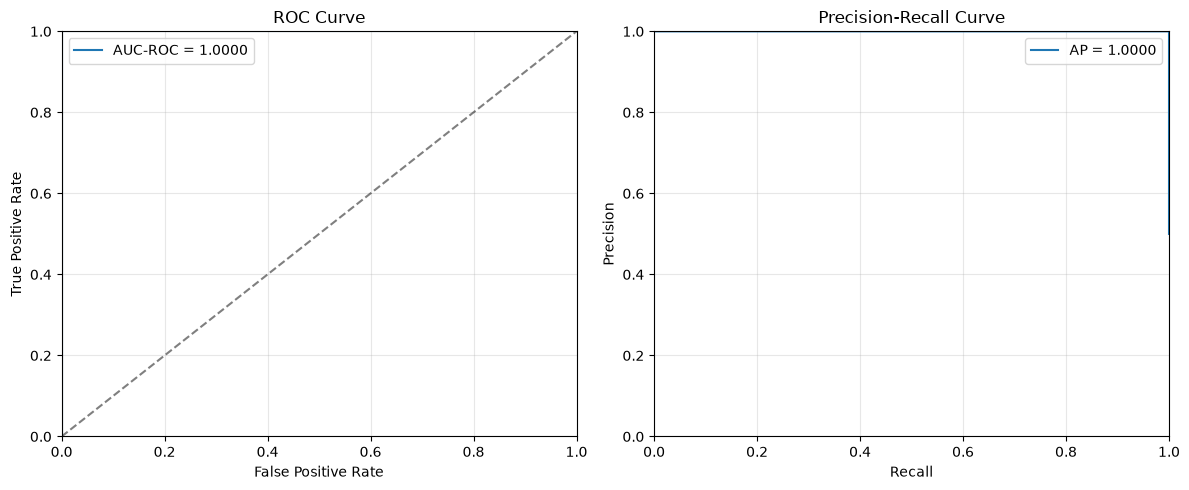

In [11]:
roc_auc, pr_auc = plot_roc_pr_curves(y, y_hat)